# LSTM + XGBoost Precipitation Forecasting — Static Configuration

This notebook is a fixed-configuration version of the LSTM-XGBoost ensemble pipeline.
Differences from the exploratory version:

- **No randomized hyperparameter search.** XGBoost's hyperparameters are hardcoded to the
  values that a prior random + refinement search converged on and validated repeatedly.
- **A single ensemble strategy** (Inverse-RMSE weighting) instead of comparing several
  candidates and auto-selecting a winner.
- **Extra evaluation metrics**: Pearson correlation, explained variance, prediction bias
  (mean error), residual distribution statistics, improvement percentage over the
  reproduced baseline, and a rainfall-intensity breakdown (performance by rain-amount
  bucket).

Data, preprocessing (Box-Cox + Min-Max scaling), and the LSTM/XGBoost architectures are
unchanged from the exploratory notebook. The train/test split is built the same way the
baseline code does it: the raw series is split at DATA_CUTOFF first, then each half is
windowed separately (70-step window/lag), with no lookback context borrowed across the
cutoff. This means the first 70 days of the test period are consumed purely as context
and are never scored, matching the baseline exactly rather than the ~70-day-larger test
set the earlier version of this notebook used. LSTM and XGBoost still share the same
test targets day for day, which is required for the ensemble step to combine them
correctly.


In [1]:
import math
import time
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import boxcox, skew, kurtosis, pearsonr
from scipy.special import inv_boxcox
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    explained_variance_score,
)
import xgboost as xgb
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout, Input

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print("Imports ready.")


Imports ready.


In [2]:
# ---------------------------------------------------------------------------
# Box-Cox transform helpers (operate on data+1 so zero-rain days are valid)
# ---------------------------------------------------------------------------
def boxcox1p(data):
    p1data = data + 1
    bcdata, bclambda = boxcox(p1data)
    return bcdata, bclambda

def inv_boxcox1p(bcdata, bclambda):
    return inv_boxcox(bcdata, bclambda) - 1


def split_sequences(series, window):
    """Sliding window: x[i] = series[i:i+window], y[i] = series[i+window]."""
    x, y = [], []
    for i in range(len(series)):
        end = i + window
        if end > len(series) - 1:
            break
        x.append(series[i:end])
        y.append(series[end])
    return np.array(x), np.array(y)


def safe_mape(y_true, y_pred, min_actual=0.1):
    """Mean absolute percentage error, computed only on days with at least
    min_actual inches of observed rain. Days at or near zero are excluded,
    since dividing by a near-zero actual value produces a huge or undefined
    percentage that would dominate the average without saying anything
    useful. min_actual=0.1 matches this dataset's recording precision
    (values are reported to the nearest 0.1 inch).
    """
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = y_true >= min_actual
    if mask.sum() == 0:
        return float('nan'), 0
    pct_errors = np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])
    return float(np.mean(pct_errors) * 100.0), int(mask.sum())


def compute_sample_weights(y_boxcox, lambda_value, floor=0.01):
    """Heavier rain days get more weight during XGBoost training so the
    model is not dominated by the large share of zero/near-zero days."""
    y_orig = inv_boxcox1p(np.asarray(y_boxcox, dtype=float), lambda_value)
    y_orig = np.maximum(y_orig, 0.0)
    return np.sqrt(y_orig + floor)


# ---------------------------------------------------------------------------
# Extra evaluation metrics
# ---------------------------------------------------------------------------
def prediction_bias(y_true, y_pred):
    """Mean (signed) error: mean(pred - true). Positive means the model
    over-predicts on average, negative means it under-predicts. Unlike MAE
    this does not take an absolute value, so it reveals systematic bias
    that MAE/RMSE hide."""
    return float(np.mean(np.asarray(y_pred, dtype=float) - np.asarray(y_true, dtype=float)))


def residual_statistics(y_true, y_pred):
    """Descriptive statistics of the residual (pred - true) distribution."""
    resid = np.asarray(y_pred, dtype=float) - np.asarray(y_true, dtype=float)
    return {
        'mean': float(np.mean(resid)),
        'std': float(np.std(resid)),
        'skew': float(skew(resid)),
        'kurtosis': float(kurtosis(resid)),
        'min': float(np.min(resid)),
        'max': float(np.max(resid)),
    }


def improvement_percentage(baseline_value, new_value):
    """Percent reduction of new_value relative to baseline_value (positive
    = improvement, e.g. lower RMSE/MAE/MAPE)."""
    if baseline_value == 0:
        return float('nan')
    return float((baseline_value - new_value) / baseline_value * 100.0)


RAIN_INTENSITY_BINS = [-np.inf, 1e-9, 0.2, 0.5, np.inf]
RAIN_INTENSITY_LABELS = ['No Rain (0 in)', 'Light (0-0.2 in)', 'Moderate (0.2-0.5 in)', 'Heavy (>0.5 in)']

def rainfall_intensity_performance(y_true, y_pred):
    """RMSE/MAE per rainfall-intensity bucket. MAPE is only meaningful for
    buckets with nonzero actuals, so it is left out of the No Rain row."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    buckets = np.asarray(pd.cut(y_true, bins=RAIN_INTENSITY_BINS, labels=RAIN_INTENSITY_LABELS))
    rows = []
    for label in RAIN_INTENSITY_LABELS:
        mask = (buckets == label)
        n = int(mask.sum())
        if n == 0:
            rows.append({'Intensity': label, 'N': 0, 'RMSE': float('nan'), 'MAE': float('nan'), 'MAPE (%)': float('nan')})
            continue
        rmse_b = math.sqrt(mean_squared_error(y_true[mask], y_pred[mask]))
        mae_b = mean_absolute_error(y_true[mask], y_pred[mask])
        if label == 'No Rain (0 in)':
            mape_b = float('nan')
        else:
            mape_b, _ = safe_mape(y_true[mask], y_pred[mask], min_actual=1e-9)
        rows.append({'Intensity': label, 'N': n, 'RMSE': rmse_b, 'MAE': mae_b, 'MAPE (%)': mape_b})
    return pd.DataFrame(rows)


def evaluate_all(y_true, y_pred, label):
    """One consolidated evaluation: RMSE, MAE, MAPE, R2, Pearson r,
    explained variance, and prediction bias."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    rmse = math.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    mape, mape_n = safe_mape(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    corr, _ = pearsonr(y_true, y_pred)
    expl_var = explained_variance_score(y_true, y_pred)
    bias = prediction_bias(y_true, y_pred)
    resid_stats = residual_statistics(y_true, y_pred)
    result = {
        'label': label,
        'rmse': rmse,
        'mae': mae,
        'mape': mape,
        'mape_n': mape_n,
        'r2': r2,
        'pearson_r': float(corr),
        'explained_variance': float(expl_var),
        'bias': bias,
        'residual_stats': resid_stats,
    }
    print(f"\n{label} evaluation:")
    print(f"  RMSE:                {rmse:.4f}")
    print(f"  MAE:                 {mae:.4f}")
    print(f"  MAPE:                {mape:.2f}% (on {mape_n} days >= 0.1 in)")
    print(f"  R2:                  {r2:.4f}")
    print(f"  Pearson r:           {corr:.4f}")
    print(f"  Explained Variance:  {expl_var:.4f}")
    print(f"  Prediction Bias:     {bias:+.4f} in (mean error, pred - true)")
    print(f"  Residual std/skew/kurtosis: {resid_stats['std']:.4f} / {resid_stats['skew']:.4f} / {resid_stats['kurtosis']:.4f}")
    return result

print("Utility functions defined.")


Utility functions defined.


In [3]:
# ---------------------------------------------------------------------------
# Fixed configuration (no search, no randomness in the hyperparameters)
# ---------------------------------------------------------------------------
TRAIN_DATA_CANDIDATES = ['2619492.csv', 'Data/2619492.csv', 'content/2619492.csv']

DATA_CUTOFF = 9058              # Chronological split point: train on [0:9058], test on [9058:]
TOTAL_DATA_LENGTH = 10988       # Total data points used for creating sequences
WINDOW_SIZE = 70                # Lookback window/lag, shared by LSTM and XGBoost
ENSEMBLE_VALIDATION_FRACTION = 0.08  # Fraction of training data held out to fit ensemble weights

LSTM_UNITS_LAYER1 = 32
LSTM_UNITS_LAYER2 = 32
LSTM_DENSE_UNITS = 16
LSTM_DROPOUT = 0.5
LSTM_EPOCHS = 100
LSTM_BATCH_SIZE = 60
LSTM_LEARNING_RATE = 1e-7
LSTM_MOMENTUM = 0.9

# XGBoost hyperparameters, fixed to values a prior randomized + refinement
# search converged on repeatedly across independent runs on this dataset.
XGB_STATIC_PARAMS = {
    'n_estimators': 1000,
    'max_depth': 2,
    'learning_rate': 0.05,
    'subsample': 0.7,
    'colsample_bytree': 0.6,
    'min_child_weight': 8,
    'gamma': 0.0,
    'reg_alpha': 0.05,
    'reg_lambda': 1.0,
}
XGB_HUBER_SLOPE = 0.5

# Reproduced baseline (fixed LSTM-only model, same dataset/split/preprocessing),
# used as the reference point for Improvement Percentage below.
BASELINE_RMSE = 6.2009
BASELINE_MAE = 2.3244
BASELINE_MAPE = 81.10

MODEL_DIR = Path("models") / "v2_static"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Configuration set.")
print(f"  XGBoost params: {XGB_STATIC_PARAMS} (huber_slope={XGB_HUBER_SLOPE})")
print(f"  Baseline reference: RMSE={BASELINE_RMSE}, MAE={BASELINE_MAE}, MAPE={BASELINE_MAPE}%")


Configuration set.
  XGBoost params: {'n_estimators': 1000, 'max_depth': 2, 'learning_rate': 0.05, 'subsample': 0.7, 'colsample_bytree': 0.6, 'min_child_weight': 8, 'gamma': 0.0, 'reg_alpha': 0.05, 'reg_lambda': 1.0} (huber_slope=0.5)
  Baseline reference: RMSE=6.2009, MAE=2.3244, MAPE=81.1%


In [4]:
# ---------------------------------------------------------------------------
# Load data and apply Box-Cox transform (lambda estimated on the training
# portion only, then applied to the whole series to avoid leakage)
# ---------------------------------------------------------------------------
csv_path = next((p for p in TRAIN_DATA_CANDIDATES if Path(p).exists()), None)
if csv_path is None:
    raise FileNotFoundError(f"Could not find training data. Searched: {TRAIN_DATA_CANDIDATES}")

rainfall = pd.read_csv(csv_path)
rainfall["DATE"] = pd.to_datetime(rainfall["DATE"], dayfirst=True)
rainfall = rainfall.set_index('DATE')
print(f"Loaded {len(rainfall)} records from {csv_path}")

_, lam_value = boxcox1p(rainfall.PRCP.iloc[:DATA_CUTOFF])
inv_data = boxcox(rainfall.PRCP.to_numpy() + 1, lmbda=lam_value)
print(f"Box-Cox lambda (fit on train only): {lam_value:.6f}")

# LSTM works on Min-Max scaled Box-Cox values (gradient descent needs a
# bounded scale). XGBoost is scale-invariant so it uses the Box-Cox values
# directly, unscaled -- this matches the exploratory notebook's design.
scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(inv_data[:DATA_CUTOFF].reshape(-1, 1))
rain_data_scaled = scaler.transform(inv_data.reshape(-1, 1))[:, 0]

lstm_series = rain_data_scaled[:TOTAL_DATA_LENGTH]
xgb_series = inv_data[:TOTAL_DATA_LENGTH]

print(f"Series length used for modeling: {len(lstm_series)}")


Loaded 11323 records from 2619492.csv
Box-Cox lambda (fit on train only): -1.438692
Series length used for modeling: 10988


In [5]:
# ---------------------------------------------------------------------------
# Build LSTM and XGBoost feature/target arrays the same way the baseline
# code does: split the raw series into train/test at DATA_CUTOFF *first*,
# then window each half separately, with no lookback context borrowed
# across the cutoff. This means the first WINDOW_SIZE (70) days of the
# test period are consumed purely as context and are never scored -- the
# first scored test day is DATA_CUTOFF + WINDOW_SIZE, matching the
# baseline's own test-set construction exactly (previously this notebook
# windowed the full series continuously and scored from DATA_CUTOFF
# itself, which gave 70 more test days than the baseline's method can
# produce; see the panel change request for the measured effect of that
# difference).
# ---------------------------------------------------------------------------
lstm_train_series = lstm_series[:DATA_CUTOFF]
lstm_test_series = lstm_series[DATA_CUTOFF:]
xgb_train_series = xgb_series[:DATA_CUTOFF]
xgb_test_series = xgb_series[DATA_CUTOFF:]

x_train, y_train = split_sequences(lstm_train_series, WINDOW_SIZE)
x_test, y_test = split_sequences(lstm_test_series, WINDOW_SIZE)
x_train = x_train.reshape(-1, WINDOW_SIZE, 1)
x_test = x_test.reshape(-1, WINDOW_SIZE, 1)

x_train_lag, y_train_lag = split_sequences(xgb_train_series, WINDOW_SIZE)
x_test_lag, y_test_lag = split_sequences(xgb_test_series, WINDOW_SIZE)

print(f"LSTM   train/test: {x_train.shape} / {x_test.shape}")
print(f"XGBoost train/test: {x_train_lag.shape} / {x_test_lag.shape}")
assert len(x_test) == len(x_test_lag), "LSTM and XGBoost test sets must be the same length"


LSTM   train/test: (8988, 70, 1) / (1860, 70, 1)
XGBoost train/test: (8988, 70) / (1860, 70)


In [6]:
# ---------------------------------------------------------------------------
# LSTM model: fixed architecture, fixed hyperparameters
# ---------------------------------------------------------------------------
model = Sequential()
model.add(Input(shape=(WINDOW_SIZE, 1)))
model.add(LSTM(LSTM_UNITS_LAYER1, activation='tanh', return_sequences=True))
model.add(Dropout(LSTM_DROPOUT))
model.add(LSTM(LSTM_UNITS_LAYER2, activation='relu'))
model.add(Dropout(LSTM_DROPOUT))
model.add(Dense(LSTM_DENSE_UNITS, activation='relu'))
model.add(Dense(1, activation='relu'))

lr_schedule = tf.keras.callbacks.LearningRateScheduler(
    lambda epoch: LSTM_LEARNING_RATE * 10 ** (epoch / 40))
optimizer = tf.keras.optimizers.SGD(learning_rate=LSTM_LEARNING_RATE, momentum=LSTM_MOMENTUM)
model.compile(loss=tf.keras.losses.Huber(), optimizer=optimizer, metrics=["mean_squared_error"])
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 70, 32)         │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 70, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,217 (51.63 KB)

 Trainable params: 13,217 (51.63 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
print("Training LSTM...")
lstm_train_start = time.time()
history = model.fit(
    x_train, y_train,
    epochs=LSTM_EPOCHS, batch_size=LSTM_BATCH_SIZE, verbose=1,
    validation_data=(x_train, y_train), callbacks=[lr_schedule],
)
lstm_train_seconds = time.time() - lstm_train_start
print(f"LSTM training complete in {lstm_train_seconds:.1f}s")


Training LSTM...
Epoch 1/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 17s 78ms/step - loss: 0.1142 - mean_squared_error: 0.2284 - val_loss: 0.1155 - val_mean_squared_error: 0.2310 - learning_rate: 1.0000e-07
Epoch 2/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 13s 87ms/step - loss: 0.1142 - mean_squared_error: 0.2284 - val_loss: 0.1155 - val_mean_squared_error: 0.2310 - learning_rate: 1.0593e-07
Epoch 3/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 11s 75ms/step - loss: 0.1141 - mean_squared_error: 0.2281 - val_loss: 0.1155 - val_mean_squared_error: 0.2310 - learning_rate: 1.1220e-07
Epoch 4/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 11s 70ms/step - loss: 0.1141 - mean_squared_error: 0.2283 - val_loss: 0.1155 - val_mean_squared_error: 0.2310 - learning_rate: 1.1885e-07
Epoch 5/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 12s 77ms/step - loss: 0.1141 - mean_squared_error: 0.2282 - val_loss: 0.1155 - val_mean_squared_error: 0.2310 - learning_rate: 1.2589e-07
Epoch 6/100
150/150 ━━━━━━━━━━━━━━━━━━━━ 10s 63ms/step - loss: 0.1141 - mean_squared_err

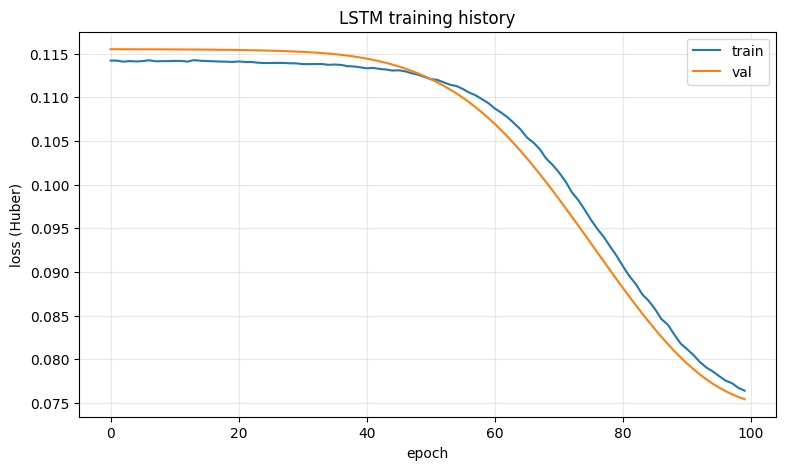

In [8]:
plt.figure(figsize=(9, 5))
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')
plt.xlabel('epoch')
plt.ylabel('loss (Huber)')
plt.title('LSTM training history')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [9]:
# ---------------------------------------------------------------------------
# Ground-truth test targets, in original precipitation units. Both models
# share the same test targets day for day, so there is a single true y_test_orig.
# ---------------------------------------------------------------------------
y_test_bc = scaler.inverse_transform(y_test.reshape(-1, 1))[:, 0]
y_test_orig = inv_boxcox1p(y_test_bc, lam_value)

y_test_lag_orig = inv_boxcox1p(y_test_lag, lam_value)
assert np.allclose(y_test_orig, y_test_lag_orig, atol=1e-6), "LSTM and XGBoost targets must match"


In [10]:
# ---------------------------------------------------------------------------
# LSTM evaluation
# ---------------------------------------------------------------------------
lstm_predict_start = time.time()
lstm_pred_scaled = model.predict(x_test, verbose=0)
lstm_predict_seconds = time.time() - lstm_predict_start

lstm_pred_bc = scaler.inverse_transform(lstm_pred_scaled)[:, 0]
lstm_pred_orig = inv_boxcox1p(lstm_pred_bc, lam_value)

lstm_eval = evaluate_all(y_test_orig, lstm_pred_orig, "LSTM (standalone)")
lstm_intensity = rainfall_intensity_performance(y_test_orig, lstm_pred_orig)
print("\nRainfall-Intensity Performance (LSTM):")
print(lstm_intensity.to_string(index=False))



LSTM (standalone) evaluation:
  RMSE:                5.9066
  MAE:                 2.2935
  MAPE:                79.03% (on 784 days >= 0.1 in)
  R2:                  -0.1369
  Pearson r:           -0.0067
  Explained Variance:  -0.0000
  Prediction Bias:     -2.0491 in (mean error, pred - true)
  Residual std/skew/kurtosis: 5.5398 / -4.5986 / 34.2720

Rainfall-Intensity Performance (LSTM):
            Intensity    N      RMSE      MAE  MAPE (%)
       No Rain (0 in) 1076  0.211460 0.211209       NaN
     Light (0-0.2 in)    0       NaN      NaN       NaN
Moderate (0.2-0.5 in)  184  0.190456 0.163497 39.642350
      Heavy (>0.5 in)  600 10.395274 6.680957 91.114961


In [11]:
# ---------------------------------------------------------------------------
# XGBoost: fixed hyperparameters, no search. A small validation split off
# the end of the training data is still used for early stopping (this
# decides *when* to stop training a single fixed configuration -- it is
# not a hyperparameter search).
# ---------------------------------------------------------------------------
n_val = max(256, int(len(x_train_lag) * 0.12))
x_tr, x_val = x_train_lag[:-n_val], x_train_lag[-n_val:]
y_tr, y_val = y_train_lag[:-n_val], y_train_lag[-n_val:]

sample_weight_tr = compute_sample_weights(y_tr, lam_value)
sample_weight_val = compute_sample_weights(y_val, lam_value)

xgb_model = xgb.XGBRegressor(
    objective='reg:pseudohubererror',
    huber_slope=XGB_HUBER_SLOPE,
    eval_metric='rmse',
    random_state=RANDOM_STATE,
    n_jobs=-1,
    tree_method='hist',
    early_stopping_rounds=60,
    **XGB_STATIC_PARAMS,
)

xgb_train_start = time.time()
xgb_model.fit(
    x_tr, y_tr,
    sample_weight=sample_weight_tr,
    eval_set=[(x_val, y_val)],
    sample_weight_eval_set=[sample_weight_val],
    verbose=False,
)
xgb_train_seconds = time.time() - xgb_train_start
n_estimators_used = int(xgb_model.best_iteration + 1) if xgb_model.best_iteration is not None else XGB_STATIC_PARAMS['n_estimators']
print(f"XGBoost training complete in {xgb_train_seconds:.1f}s ({n_estimators_used} trees used)")


XGBoost training complete in 0.6s (131 trees used)


In [12]:
# ---------------------------------------------------------------------------
# XGBoost evaluation
# ---------------------------------------------------------------------------
xgb_predict_start = time.time()
xgb_pred_bc = xgb_model.predict(x_test_lag)
xgb_predict_seconds = time.time() - xgb_predict_start

xgb_pred_orig = inv_boxcox1p(xgb_pred_bc, lam_value)

xgb_eval = evaluate_all(y_test_orig, xgb_pred_orig, "XGBoost (standalone)")
xgb_intensity = rainfall_intensity_performance(y_test_orig, xgb_pred_orig)
print("\nRainfall-Intensity Performance (XGBoost):")
print(xgb_intensity.to_string(index=False))



XGBoost (standalone) evaluation:
  RMSE:                5.5320
  MAE:                 3.1341
  MAPE:                176.85% (on 784 days >= 0.1 in)
  R2:                  0.0028
  Pearson r:           0.0565
  Explained Variance:  0.0031
  Prediction Bias:     -0.0931 in (mean error, pred - true)
  Residual std/skew/kurtosis: 5.5312 / -4.6012 / 34.2159

Rainfall-Intensity Performance (XGBoost):
            Intensity    N     RMSE      MAE   MAPE (%)
       No Rain (0 in) 1076 2.164273 2.136310        NaN
     Light (0-0.2 in)    0      NaN      NaN        NaN
Moderate (0.2-0.5 in)  184 1.870187 1.822586 518.247262
      Heavy (>0.5 in)  600 9.240973 5.325643  72.159693


In [13]:
# ---------------------------------------------------------------------------
# Ensemble: Inverse-RMSE weighting (the single ensemble strategy used here).
# Weights are derived deterministically from validation RMSE -- no search,
# no comparison across multiple candidate strategies.
# ---------------------------------------------------------------------------
n_ens_val = max(256, int(len(x_train) * ENSEMBLE_VALIDATION_FRACTION))
x_ens_val_lstm = x_train[-n_ens_val:]
x_ens_val_xgb = x_train_lag[-n_ens_val:]
y_ens_val_lag = y_train_lag[-n_ens_val:]

lstm_val_pred_scaled = model.predict(x_ens_val_lstm, verbose=0).flatten()
lstm_val_pred_bc = scaler.inverse_transform(lstm_val_pred_scaled.reshape(-1, 1))[:, 0]
lstm_val_pred_orig = inv_boxcox1p(lstm_val_pred_bc, lam_value)

xgb_val_pred_orig = inv_boxcox1p(xgb_model.predict(x_ens_val_xgb), lam_value)
y_ens_val_orig = inv_boxcox1p(y_ens_val_lag, lam_value)

rmse_lstm_val = math.sqrt(mean_squared_error(y_ens_val_orig, lstm_val_pred_orig))
rmse_xgb_val = math.sqrt(mean_squared_error(y_ens_val_orig, xgb_val_pred_orig))

inv_w_lstm = 1.0 / rmse_lstm_val
inv_w_xgb = 1.0 / rmse_xgb_val
inv_w_sum = inv_w_lstm + inv_w_xgb
w_lstm = inv_w_lstm / inv_w_sum
w_xgb = inv_w_xgb / inv_w_sum

print(f"Ensemble validation RMSE -- LSTM: {rmse_lstm_val:.4f}, XGBoost: {rmse_xgb_val:.4f}")
print(f"Inverse-RMSE weights -- LSTM: {w_lstm:.4f}, XGBoost: {w_xgb:.4f}")

ensemble_pred_orig = w_lstm * lstm_pred_orig + w_xgb * xgb_pred_orig
ensemble_eval = evaluate_all(y_test_orig, ensemble_pred_orig, "Ensemble (Inverse-RMSE weighting)")
ensemble_intensity = rainfall_intensity_performance(y_test_orig, ensemble_pred_orig)
print("\nRainfall-Intensity Performance (Ensemble):")
print(ensemble_intensity.to_string(index=False))


Ensemble validation RMSE -- LSTM: 6.2090, XGBoost: 5.8370
Inverse-RMSE weights -- LSTM: 0.4846, XGBoost: 0.5154

Ensemble (Inverse-RMSE weighting) evaluation:
  RMSE:                5.6293
  MAE:                 2.6414
  MAPE:                105.80% (on 784 days >= 0.1 in)
  R2:                  -0.0326
  Pearson r:           0.0563
  Explained Variance:  0.0027
  Prediction Bias:     -1.0409 in (mean error, pred - true)
  Residual std/skew/kurtosis: 5.5322 / -4.6076 / 34.3195

Rainfall-Intensity Performance (Ensemble):
            Intensity    N     RMSE      MAE   MAPE (%)
       No Rain (0 in) 1076 1.216647 1.203486        NaN
     Light (0-0.2 in)    0      NaN      NaN        NaN
Moderate (0.2-0.5 in)  184 0.890671 0.860213 247.917009
      Heavy (>0.5 in)  600 9.764067 5.766263  62.223891


In [14]:
# ---------------------------------------------------------------------------
# Final comparison table
# ---------------------------------------------------------------------------
def improvement_row(evaluation):
    return {
        'RMSE improvement (%)': improvement_percentage(BASELINE_RMSE, evaluation['rmse']),
        'MAE improvement (%)': improvement_percentage(BASELINE_MAE, evaluation['mae']),
        'MAPE improvement (%)': improvement_percentage(BASELINE_MAPE, evaluation['mape']),
    }

comparison_rows = []
for evaluation in [lstm_eval, xgb_eval, ensemble_eval]:
    row = {
        'Model': evaluation['label'],
        'RMSE': evaluation['rmse'],
        'MAE': evaluation['mae'],
        'MAPE (%)': evaluation['mape'],
        'R2': evaluation['r2'],
        'Pearson r': evaluation['pearson_r'],
        'Explained Variance': evaluation['explained_variance'],
        'Bias (mean error)': evaluation['bias'],
    }
    row.update(improvement_row(evaluation))
    comparison_rows.append(row)

df_comparison = pd.DataFrame(comparison_rows)
print(f"Baseline reference (reproduced): RMSE={BASELINE_RMSE}, MAE={BASELINE_MAE}, MAPE={BASELINE_MAPE}%\n")
print(df_comparison.to_string(index=False, float_format=lambda x: f'{x:.4f}'))


Baseline reference (reproduced): RMSE=6.2009, MAE=2.3244, MAPE=81.1%

                            Model   RMSE    MAE  MAPE (%)      R2  Pearson r  Explained Variance  Bias (mean error)  RMSE improvement (%)  MAE improvement (%)  MAPE improvement (%)
                LSTM (standalone) 5.9066 2.2935   79.0347 -0.1369    -0.0067             -0.0000            -2.0491                4.7459               1.3292                2.5467
             XGBoost (standalone) 5.5320 3.1341  176.8537  0.0028     0.0565              0.0031            -0.0931               10.7877             -34.8344             -118.0687
Ensemble (Inverse-RMSE weighting) 5.6293 2.6414  105.8049 -0.0326     0.0563              0.0027            -1.0409                9.2185             -13.6375              -30.4623


In [15]:
# ---------------------------------------------------------------------------
# Rainfall-Intensity Performance (all models, side by side)
# ---------------------------------------------------------------------------
intensity_tables = {
    'LSTM': lstm_intensity,
    'XGBoost': xgb_intensity,
    'Ensemble': ensemble_intensity,
}
for name, table in intensity_tables.items():
    print(f"\n{name}:")
    print(table.to_string(index=False, float_format=lambda x: f'{x:.4f}'))



LSTM:
            Intensity    N    RMSE    MAE  MAPE (%)
       No Rain (0 in) 1076  0.2115 0.2112       NaN
     Light (0-0.2 in)    0     NaN    NaN       NaN
Moderate (0.2-0.5 in)  184  0.1905 0.1635   39.6424
      Heavy (>0.5 in)  600 10.3953 6.6810   91.1150

XGBoost:
            Intensity    N   RMSE    MAE  MAPE (%)
       No Rain (0 in) 1076 2.1643 2.1363       NaN
     Light (0-0.2 in)    0    NaN    NaN       NaN
Moderate (0.2-0.5 in)  184 1.8702 1.8226  518.2473
      Heavy (>0.5 in)  600 9.2410 5.3256   72.1597

Ensemble:
            Intensity    N   RMSE    MAE  MAPE (%)
       No Rain (0 in) 1076 1.2166 1.2035       NaN
     Light (0-0.2 in)    0    NaN    NaN       NaN
Moderate (0.2-0.5 in)  184 0.8907 0.8602  247.9170
      Heavy (>0.5 in)  600 9.7641 5.7663   62.2239


                            Model    mean    std    skew  kurtosis      min    max
                LSTM (standalone) -2.0491 5.5398 -4.5986   34.2720 -80.0947 0.2323
             XGBoost (standalone) -0.0931 5.5312 -4.6012   34.2159 -77.7093 3.9384
Ensemble (Inverse-RMSE weighting) -1.0409 5.5322 -4.6076   34.3195 -78.8652 2.1285


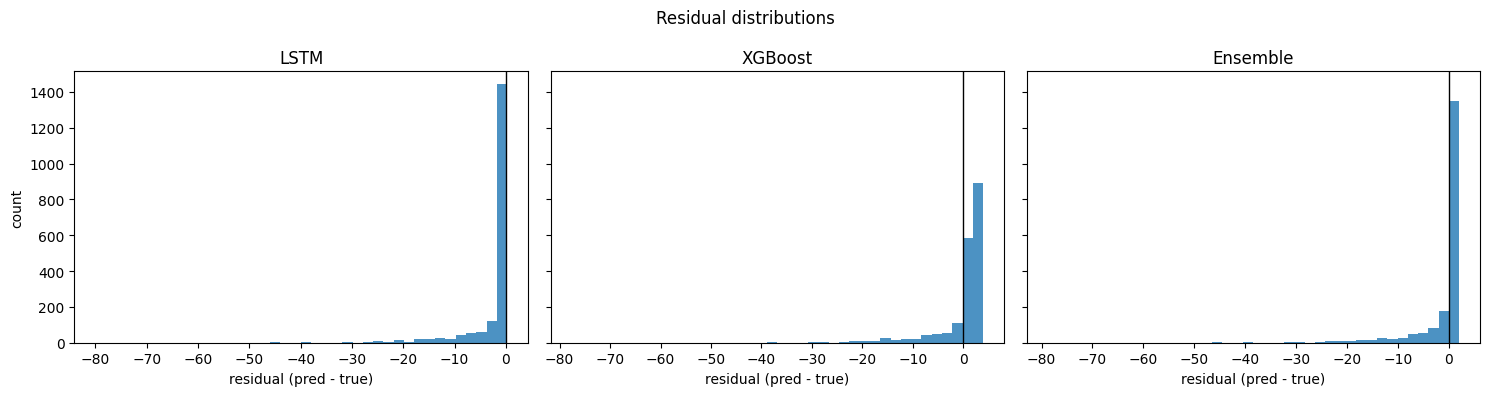

In [16]:
# ---------------------------------------------------------------------------
# Error Distribution / Residual Statistics (all models, side by side)
# ---------------------------------------------------------------------------
residual_rows = []
for evaluation in [lstm_eval, xgb_eval, ensemble_eval]:
    row = {'Model': evaluation['label']}
    row.update(evaluation['residual_stats'])
    residual_rows.append(row)

df_residuals = pd.DataFrame(residual_rows)
print(df_residuals.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (name, pred) in zip(
    axes,
    [('LSTM', lstm_pred_orig), ('XGBoost', xgb_pred_orig), ('Ensemble', ensemble_pred_orig)],
):
    resid = np.asarray(pred) - np.asarray(y_test_orig)
    ax.hist(resid, bins=40, alpha=0.8)
    ax.axvline(0, color='k', linewidth=1)
    ax.set_title(name)
    ax.set_xlabel('residual (pred - true)')
axes[0].set_ylabel('count')
plt.suptitle('Residual distributions')
plt.tight_layout()
plt.show()


In [17]:
# ---------------------------------------------------------------------------
# Save results
# ---------------------------------------------------------------------------
results = {
    'model_type': 'LSTM_XGBoost_Ensemble_static',
    'lstm_config': {
        'window_size': WINDOW_SIZE,
        'units_layer1': LSTM_UNITS_LAYER1,
        'units_layer2': LSTM_UNITS_LAYER2,
        'dense_units': LSTM_DENSE_UNITS,
        'dropout': LSTM_DROPOUT,
        'epochs': LSTM_EPOCHS,
        'batch_size': LSTM_BATCH_SIZE,
        'learning_rate': LSTM_LEARNING_RATE,
        'momentum': LSTM_MOMENTUM,
    },
    'xgboost_config': dict(XGB_STATIC_PARAMS, huber_slope=XGB_HUBER_SLOPE, lag_window=WINDOW_SIZE,
                           n_estimators_used=n_estimators_used),
    'preprocessing': {'box_cox_lambda': float(lam_value), 'scaler_type': 'MinMaxScaler'},
    'ensemble': {'strategy': 'Inverse RMSE weighting', 'weight_lstm': float(w_lstm), 'weight_xgb': float(w_xgb)},
    'baseline_reference': {'rmse': BASELINE_RMSE, 'mae': BASELINE_MAE, 'mape': BASELINE_MAPE},
    'evaluation': {
        'lstm': {k: v for k, v in lstm_eval.items() if k != 'label'},
        'xgboost': {k: v for k, v in xgb_eval.items() if k != 'label'},
        'ensemble': {k: v for k, v in ensemble_eval.items() if k != 'label'},
    },
    'rainfall_intensity_performance': {
        'lstm': lstm_intensity.to_dict(orient='records'),
        'xgboost': xgb_intensity.to_dict(orient='records'),
        'ensemble': ensemble_intensity.to_dict(orient='records'),
    },
    'computational_cost': {
        'lstm_train_seconds': lstm_train_seconds,
        'lstm_predict_seconds': lstm_predict_seconds,
        'xgboost_train_seconds': xgb_train_seconds,
        'xgboost_predict_seconds': xgb_predict_seconds,
    },
}

with open(MODEL_DIR / 'metadata.json', 'w') as f:
    json.dump(results, f, indent=4, default=float)

print(f"Saved results to {MODEL_DIR / 'metadata.json'}")


Saved results to models\v2_static\metadata.json
